In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/santhoshkumarpuppala/american-bankruptcy-data/american_bankruptcy_dataset.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PowerTransformer,RobustScaler,OneHotEncoder
from sklearn.metrics import accuracy_score,recall_score,f1_score,precision_score,roc_auc_score,confusion_matrix,classification_report
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from collections import Counter
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input,BatchNormalization
from sklearn.utils.class_weight import compute_class_weight
import optuna
from tensorflow.keras.optimizers import RMSprop,SGD,Adam
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
df = pd.read_csv(r"/kaggle/input/datasets/santhoshkumarpuppala/american-bankruptcy-data/american_bankruptcy_dataset.csv")
pd.set_option('display.max_columns', None)

In [4]:
df

,company_name,fyear,status_label,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,Division,MajorGroup
0,C_1,1999.0,alive,511267.0,740998.000,833107.0,180447.000,18373.000,70658.000,89031.000,191226.00,336.018,163816.000,35.163,201026.000,128.348,1024333.000,372.7519,401483.000,1024333.000,935302.00,D,37
1,C_1,2000.0,alive,485856.0,701.854,713811.0,179987.000,18577.000,45.790,64367.000,160444.00,320.590,125392.000,18531.000,204065.000,115187.000,874255.000,377.1180,361642.000,874255.000,809888.00,D,37
2,C_1,2001.0,alive,436656.0,710199.000,526477.0,217699.000,22496.000,4711.000,27207.000,112244.00,286588.000,150464.000,-58.939,139.603,77528.000,638721.000,364.5928,399964.000,638721.000,611514.00,D,37
3,C_1,2002.0,alive,396412.0,686.621,496747.0,164658.000,27172.000,3573.000,30745.000,109.59,259954.000,203575.000,-12.410,124106.000,66322.000,606337.000,143.3295,391633.000,606337.000,575592.00,D,37
4,C_1,2003.0,alive,432204.0,709.292,523302.0,248666.000,26.680,20811.000,47.491,128656.00,247245.000,131261.000,3504.000,131884.000,104661.000,651.958,308.9071,407608.000,651.958,604467.00,D,37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78677,C_8971,2014.0,alive,233211.0,1099101.000,43338.0,184666.000,14094.000,31521.000,45615.000,60885.00,3.376,28197.000,25261.000,28095.000,22846.000,104223.000,756.4827,225887.000,104223.000,58608.00,E,44
78678,C_8971,2015.0,alive,105559.0,1865926.000,59184.0,770.103,42592.000,159541.000,202133.000,231969.00,2.288,88.128,129688.000,157783.000,54611.000,291153.000,527575.0000,880327.000,291153.000,89.02,E,44
78679,C_8971,2016.0,alive,63971.0,1746235.000,69074.0,683985.000,65057.000,13.994,79051.000,100784.00,2.581,85765.000,-1442.000,156341.000,42467.000,169858.000,578.8868,770.233,169858.000,90807.00,E,44
78680,C_8971,2017.0,alive,135207.0,1736.110,66527.0,694035.000,65.330,3841.000,69171.000,95357.00,2013.000,82.010,-20401.000,135941.000,27217.000,161884.000,412.6241,776697.000,161884.000,92713.00,E,44


In [5]:
df['fyear'].value_counts()

fyear
1999.0    5308
2000.0    5226
2001.0    4897
2002.0    4651
2003.0    4417
2004.0    4348
2005.0    4205
2006.0    4128
2007.0    4009
2008.0    3857
2009.0    3743
2010.0    3625
2011.0    3513
2014.0    3504
2012.0    3485
2013.0    3484
2015.0    3354
2016.0    3191
2017.0    3014
2018.0    2723
Name: count, dtype: int64

In [6]:
df.rename(columns={
    "X1": "Current_Assets",
    "X2": "Cost_of_Goods_Sold",
    "X3": "Depreciation_and_Amortization",
    "X4": "EBITDA",
    "X5": "Inventory",
    "X6": "Net_Income",
    "X7": "Total_Receivables",
    "X8": "Market_Value",
    "X9": "Net_Sales",
    "X10": "Total_Assets",
    "X11": "Long_Term_Debt",
    "X12": "EBIT",
    "X13": "Gross_Profit",
    "X14": "Current_Liabilities",
    "X15": "Retained_Earnings",
    "X16": "Total_Revenue",
    "X17": "Total_Liabilities",
    "X18": "Operating_Expenses"}, inplace=True)

## First we will check if the data set is having any imbalance as it is a classification problem

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fyear,78682.0,2007.506317,5.742768e+00,1.999000e+03,2002.0000,2007.0000,2012.000000,2018.0
Current_Assets,78682.0,213314.084193,7.016291e+05,-2.498000e+03,1272.0000,22016.5000,153994.000000,31322583.0
Cost_of_Goods_Sold,78682.0,599470.892747,2.065452e+06,7.000000e-03,3282.5250,43266.5000,329362.000000,67234944.0
Depreciation_and_Amortization,78682.0,379774.455090,2.021659e+06,-3.666450e+05,1439.1000,21044.5000,180821.500000,163245615.0
EBITDA,78682.0,150843.340375,7.115052e+05,-2.300000e+01,0.0000,500.0000,16010.500000,20687082.0
Inventory,78682.0,24715.653499,9.778169e+04,0.000000e+00,74.4000,1216.0000,12344.750000,4440438.0
Net_Income,78682.0,44261.768582,2.240017e+05,-5.043795e+06,-767.7500,303.0000,19097.750000,9783515.0
Total_Receivables,78682.0,69421.150571,2.847994e+05,-4.512135e+06,-9.0000,1121.9000,33256.750000,12566722.0
Market_Value,78682.0,172375.674452,6.007523e+05,-4.367571e+06,355.4325,11459.5000,109900.000000,27864399.0
Net_Sales,78682.0,51021.655540,2.204076e+05,0.000000e+00,0.0000,675.0000,16771.750000,11918508.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   company_name                   78682 non-null  object 
 1   fyear                          78682 non-null  float64
 2   status_label                   78682 non-null  object 
 3   Current_Assets                 78682 non-null  float64
 4   Cost_of_Goods_Sold             78682 non-null  float64
 5   Depreciation_and_Amortization  78682 non-null  float64
 6   EBITDA                         78682 non-null  float64
 7   Inventory                      78682 non-null  float64
 8   Net_Income                     78682 non-null  float64
 9   Total_Receivables              78682 non-null  float64
 10  Market_Value                   78682 non-null  float64
 11  Net_Sales                      78682 non-null  float64
 12  Total_Assets                   78682 non-null 

In [9]:
print((df["Current_Liabilities"] == df["Total_Liabilities"]).all())

True


In [10]:
print(df[["Current_Liabilities", "Total_Liabilities"]].corr())

                     Current_Liabilities  Total_Liabilities
Current_Liabilities                  1.0                1.0
Total_Liabilities                    1.0                1.0


In [11]:
print((df["Current_Assets"] == df["Total_Assets"]).all())

False


In [12]:
print(df[["Current_Assets", "Total_Assets"]].corr())

                Current_Assets  Total_Assets
Current_Assets        1.000000      0.637689
Total_Assets          0.637689      1.000000


The both the current_liabilities and total_liabilities have same number of rows.

This means they provide identical information to the model. Keeping both does not add any new information. It can be dropped

In [13]:
df.drop(columns=["Total_Liabilities"], inplace=True)

## Outliers

In [16]:
numeric_cols = df.select_dtypes(include="number").columns
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = ((df[numeric_cols] < lower_bound) |(df[numeric_cols] > upper_bound))
outlier_count = outliers.sum()
print(outlier_count.sort_values(ascending=False))

EBIT                             23515
Long_Term_Debt                   22521
Net_Income                       17557
EBITDA                           15814
Total_Receivables                14868
Retained_Earnings                14727
Net_Sales                        13427
Total_Revenue                    12707
Inventory                        12001
Gross_Profit                     11885
Cost_of_Goods_Sold               11856
Current_Liabilities              11674
Depreciation_and_Amortization    11448
Total_Assets                     11297
Market_Value                     11283
Operating_Expenses               11073
Current_Assets                   10110
fyear                                0
MajorGroup                           0
dtype: int64


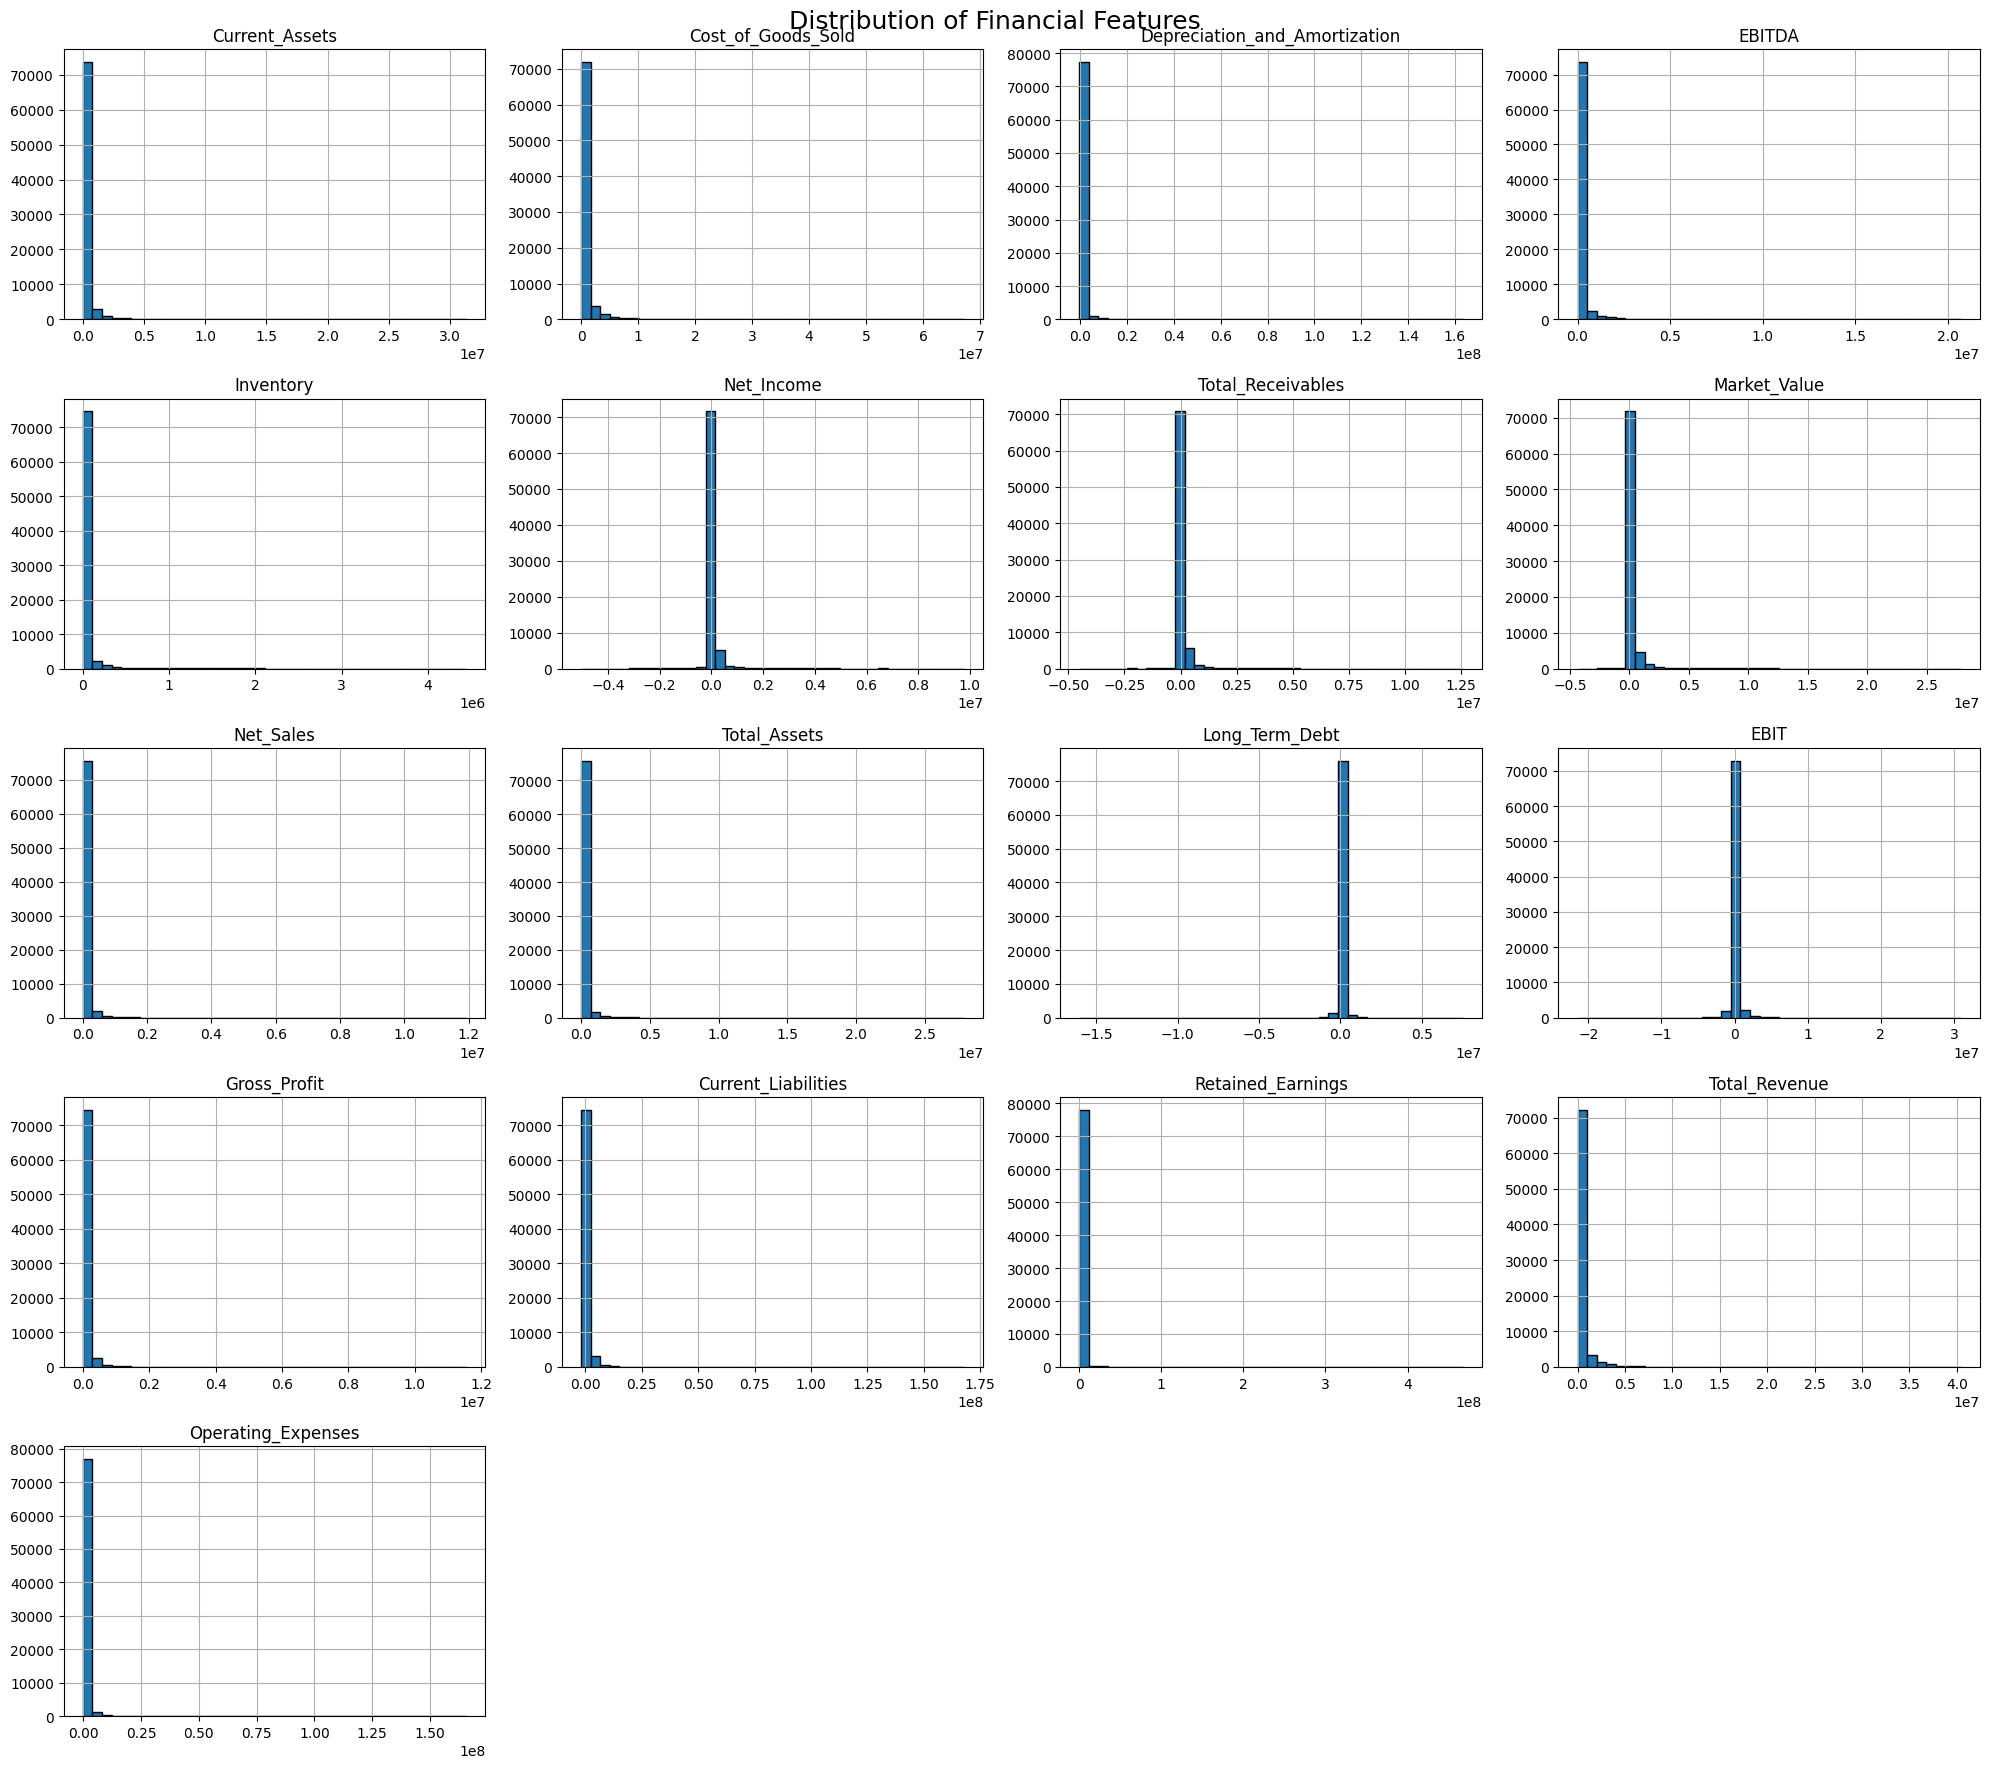

In [17]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
numeric_cols = [col for col in numeric_cols if col not in ["fyear", "MajorGroup"]]
df[numeric_cols].hist(figsize=(20, 18), bins=40, edgecolor="black")
plt.suptitle("Distribution of Financial Features", fontsize=18)
plt.tight_layout()
plt.show()

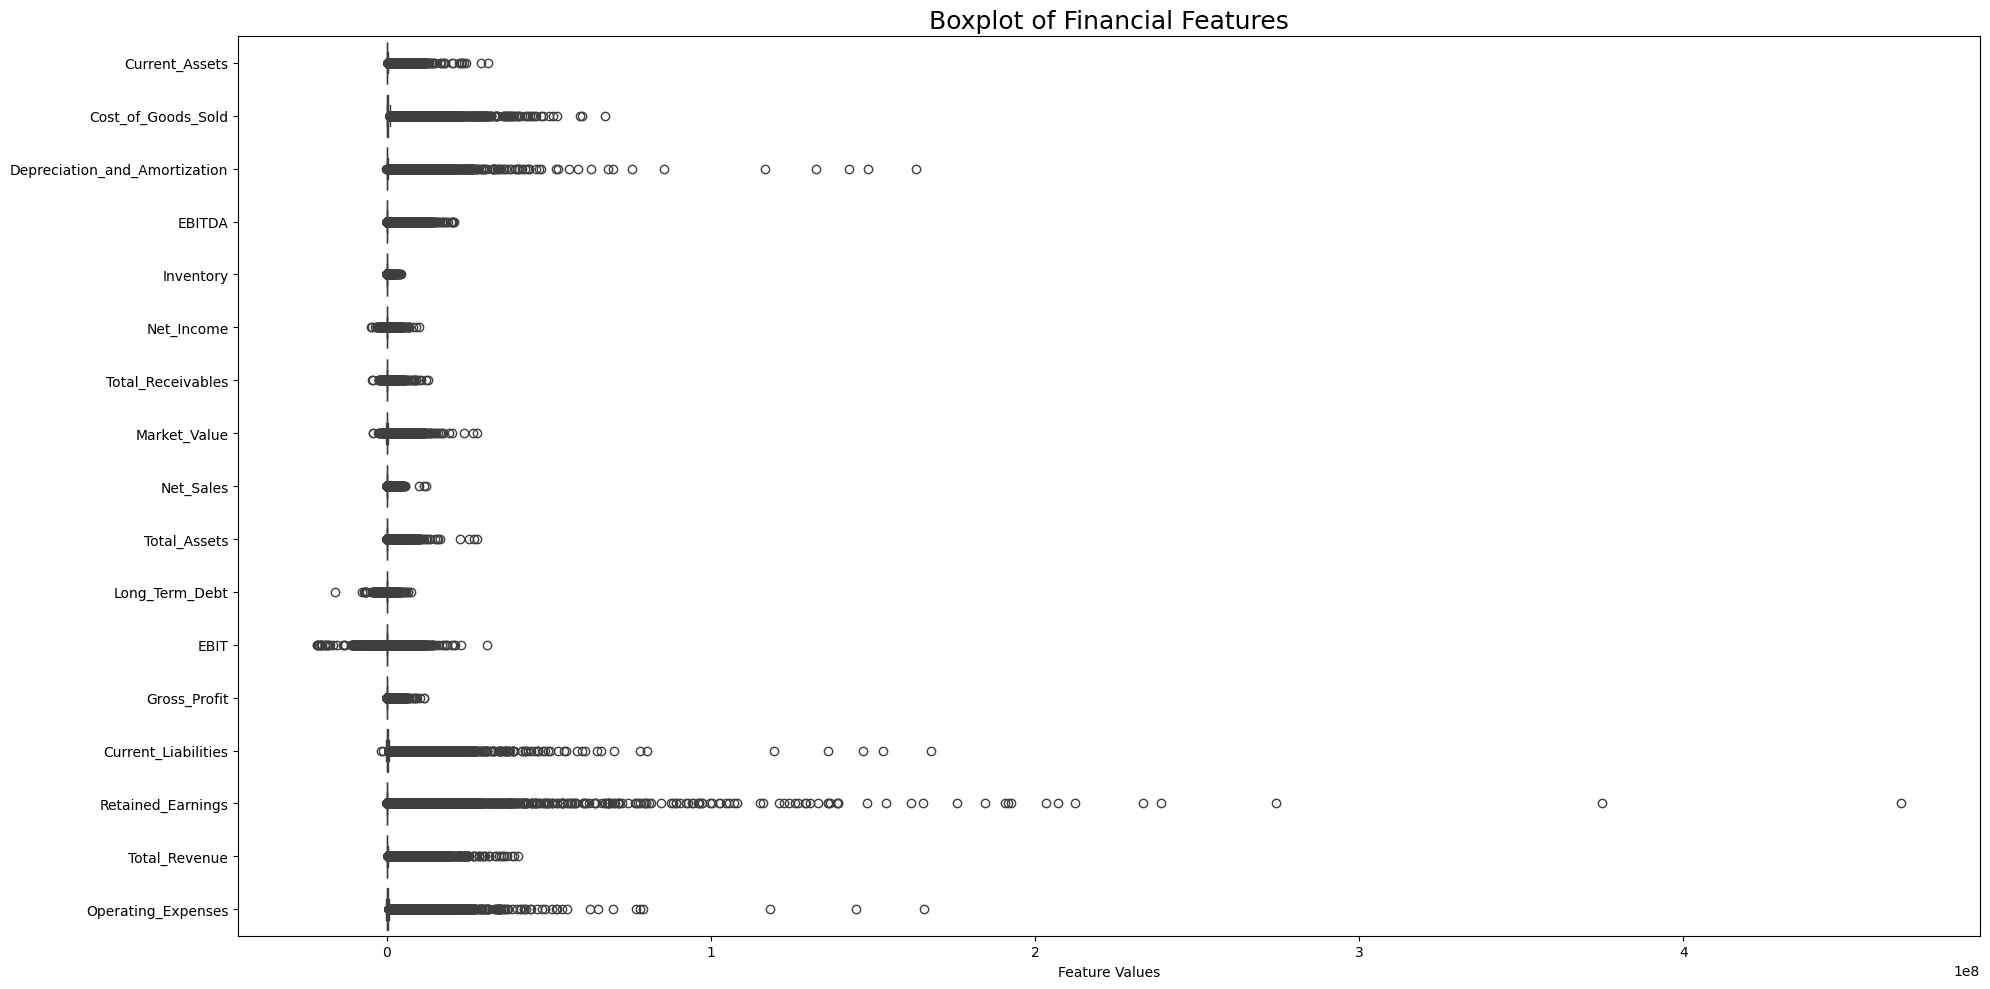

In [18]:

plt.figure(figsize=(20, 10))
sns.boxplot(data=df[numeric_cols],orient="h")
plt.title("Boxplot of Financial Features",fontsize=18)
plt.xlabel("Feature Values")
plt.tight_layout()
plt.show()


EBIT has 23,515 potential outliers.

Long-term debt has 22,521 potential outliers.


Net income has 17,557 potential outliers.

In the financial data we can have the outliers.

In financial datasets, large companies naturally have much larger assets, revenue, debt, and profits than smaller companies.

Therefore, blindly deleting these records could remove valuable financial information.

Things to do in preprocessi :
    
1.RobustScaler for scaling.

2.log transformations for highly skewed features, using a signed transformation where negative values exist.

In [19]:
print(df["MajorGroup"].nunique())
print(df["MajorGroup"].value_counts().head(20))

73
MajorGroup
73    11186
28     8458
36     7113
38     6430
35     4560
13     3264
49     2733
48     2639
37     1962
20     1838
80     1805
50     1764
59     1584
87     1578
58     1383
34     1235
51     1175
33      994
56      870
30      804
Name: count, dtype: int64


In [20]:

print("Target Variable Distribution:")

print(df["status_label"].value_counts())


Target Variable Distribution:
status_label
alive     73462
failed     5220
Name: count, dtype: int64


In [21]:

class_percentage = (df["status_label"].value_counts(normalize=True) * 100)

print(class_percentage)


status_label
alive     93.3657
failed     6.6343
Name: proportion, dtype: float64


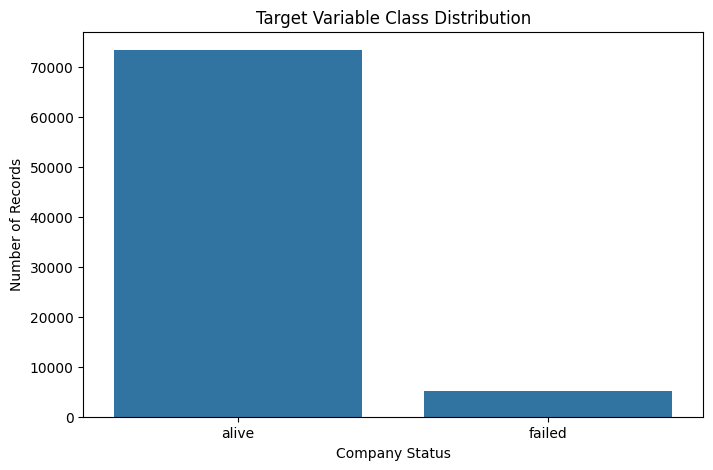

In [22]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df,x="status_label")

plt.title("Target Variable Class Distribution")
plt.xlabel("Company Status")
plt.ylabel("Number of Records")

plt.show()


As the data set is imbalanced.

1.first I will use he weighted approach and also with SMOTE.



# DATA Division

The dataset was divided using a chronological splitting approach rather than random splitting because the project focuses on predicting corporate financial distress using historical financial information. The training dataset covers 1999–2011, the validation dataset covers 2012–2014, and the testing dataset covers 2015–2018. This approach simulates a real-world prediction scenario in which a model learns from past financial records and predicts financial distress in future periods. It also reduces the risk of temporal data leakage and provides a more reliable evaluation of the model's ability to generalize to unseen future data.

Here the I am dividing the data in the three parts 

1.Train Data

2.Validation Data

3.Testing Data

We are performing chronological splitting because our project is trying to predict future corporate financial distress using past financial information.

In [8]:
train = df[df["fyear"].between(1999, 2011)]
val = df[df["fyear"].between(2012, 2014)]
test = df[df["fyear"].between(2015, 2018)]

print("Training:", train.shape)
print("Validation:", val.shape)
print("Testing:", test.shape)

Training: (55927, 23)
Validation: (10473, 23)
Testing: (12282, 23)


In [9]:
df.isna().sum()

company_name                     0
fyear                            0
status_label                     0
Current_Assets                   0
Cost_of_Goods_Sold               0
Depreciation_and_Amortization    0
EBITDA                           0
Inventory                        0
Net_Income                       0
Total_Receivables                0
Market_Value                     0
Net_Sales                        0
Total_Assets                     0
Long_Term_Debt                   0
EBIT                             0
Gross_Profit                     0
Current_Liabilities              0
Retained_Earnings                0
Total_Revenue                    0
Total_Liabilities                0
Operating_Expenses               0
Division                         0
MajorGroup                       0
dtype: int64

In [10]:
train

,company_name,fyear,status_label,Current_Assets,Cost_of_Goods_Sold,Depreciation_and_Amortization,EBITDA,Inventory,Net_Income,Total_Receivables,Market_Value,Net_Sales,Total_Assets,Long_Term_Debt,EBIT,Gross_Profit,Current_Liabilities,Retained_Earnings,Total_Revenue,Total_Liabilities,Operating_Expenses,Division,MajorGroup
0,C_1,1999.0,alive,511267.000,740998.000,833107.00,180447.0,18373.00,70658.00,89031.000,191226.00,336.018,163816.0,35.163,201026.000,128.348,1024333.000,372.7519,401483.0,1024333.000,935302.000,D,37
1,C_1,2000.0,alive,485856.000,701.854,713811.00,179987.0,18577.00,45.79,64367.000,160444.00,320.590,125392.0,18531.000,204065.000,115187.000,874255.000,377.1180,361642.0,874255.000,809888.000,D,37
2,C_1,2001.0,alive,436656.000,710199.000,526477.00,217699.0,22496.00,4711.00,27207.000,112244.00,286588.000,150464.0,-58.939,139.603,77528.000,638721.000,364.5928,399964.0,638721.000,611514.000,D,37
3,C_1,2002.0,alive,396412.000,686.621,496747.00,164658.0,27172.00,3573.00,30745.000,109.59,259954.000,203575.0,-12.410,124106.000,66322.000,606337.000,143.3295,391633.0,606337.000,575592.000,D,37
4,C_1,2003.0,alive,432204.000,709.292,523302.00,248666.0,26.68,20811.00,47.491,128656.00,247245.000,131261.0,3504.000,131884.000,104661.000,651.958,308.9071,407608.0,651.958,604467.000,D,37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78632,C_8964,2010.0,alive,215654.000,343156.000,170335.00,0.0,7564.00,32155.00,39719.000,48848.00,37372.000,44159.0,23094.000,15196.000,35684.000,219183.000,397.7911,90833.0,219183.000,179.464,D,28
78633,C_8964,2011.0,alive,242525.000,385244.000,239011.00,0.0,9119.00,51615.00,60734.000,70874.00,57.439,35799.0,34509.000,34729.000,35677.000,309885.000,513.0454,97006.0,309885.000,249151.000,D,28
78645,C_8966,2011.0,alive,1.677,18354.000,0.05,2.0,1806.00,-13.48,-11674.000,0.10,0.000,9677.0,-15668.000,-110325.000,1.500,0.150,4.2105,11677.0,0.150,11.824,D,36
78652,C_8967,2010.0,alive,13779.000,25494.000,35982.00,6036.0,1123.00,3068.00,4191.000,5169.00,4824.000,4756.0,10151.000,1668.000,3747.000,41151.000,19420.6232,13898.0,41151.000,36960.000,D,28


In [11]:
train.columns

Index(['company_name', 'fyear', 'status_label', 'Current_Assets',
       'Cost_of_Goods_Sold', 'Depreciation_and_Amortization', 'EBITDA',
       'Inventory', 'Net_Income', 'Total_Receivables', 'Market_Value',
       'Net_Sales', 'Total_Assets', 'Long_Term_Debt', 'EBIT', 'Gross_Profit',
       'Current_Liabilities', 'Retained_Earnings', 'Total_Revenue',
       'Total_Liabilities', 'Operating_Expenses', 'Division', 'MajorGroup'],
      dtype='object')

In [12]:
X_train = train.drop(columns = ['company_name','status_label'])
y_train = train['status_label']
X_val = val.drop(columns = ['company_name','status_label'])
y_val = val['status_label']
X_test = test.drop(columns = ['company_name','status_label'])
y_result = test['status_label']

In [13]:
numerical_pipeline = Pipeline([("Scaler", RobustScaler())])

In [14]:
categorical_pipeline = Pipeline([("Encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=False))])

In [15]:
numerical_features = ["Current_Assets","Cost_of_Goods_Sold","Depreciation_and_Amortization","EBITDA","Inventory","Net_Income","Total_Receivables","Market_Value","Net_Sales","Total_Assets","Long_Term_Debt",
    "EBIT","Gross_Profit","Retained_Earnings","Total_Revenue","Current_Liabilities","Operating_Expenses","fyear"]

categorical_features = ["MajorGroup",'Division']

In [16]:
preprocessor = ColumnTransformer([("Numerical", numerical_pipeline, numerical_features),("Categorical", categorical_pipeline, categorical_features)])

In [17]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

In [18]:
label_map = {'alive': 0, 'failed': 1}
y_train = train['status_label'].map(label_map)
y_val = val['status_label'].map(label_map)
y_result = test['status_label'].map(label_map)

# Class Weights approach

In [19]:
classes = np.unique(y_train)

weights = compute_class_weight(class_weight="balanced",classes=classes,y=y_train)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(0.5431387782849374), np.int64(1): np.float64(6.295249887438091)}


In [24]:
def build_model(input_shape):

    model = Sequential()
    model.add(Input(shape=(input_shape,)))

    model.add(Dense(64, activation="relu"),Dropout(0.3))

    model.add(Dense(32, activation="relu"),Dropout(0.2))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(optimizer="adam",loss="binary_crossentropy",
                  metrics=["accuracy",
                           tf.keras.metrics.Precision(name="precision"),
                           tf.keras.metrics.Recall(name="recall"),
                           tf.keras.metrics.F1Score(threshold = 0.5,name="f1_score")])

    return model

In [25]:
model_class_weights = build_model(X_train_processed.shape[1])

history_class_weights = model_class_weights.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    verbose=1)

Epoch 1/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6237 - f1_score: 0.2054 - loss: 1.4608 - precision: 0.1234 - recall: 0.6121 - val_accuracy: 0.8048 - val_f1_score: 0.2096 - val_loss: 0.5638 - val_precision: 0.1294 - val_recall: 0.5519
Epoch 2/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6425 - f1_score: 0.2337 - loss: 1.1758 - precision: 0.1408 - recall: 0.6862 - val_accuracy: 0.8214 - val_f1_score: 0.2143 - val_loss: 0.4600 - val_precision: 0.1350 - val_recall: 0.5193
Epoch 3/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6484 - f1_score: 0.2385 - loss: 1.1619 - precision: 0.1440 - recall: 0.6934 - val_accuracy: 0.7843 - val_f1_score: 0.2082 - val_loss: 0.6090 - val_precision: 0.1257 - val_recall: 0.6049
Epoch 4/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6599 - f1_score: 0.2495 - loss: 1.2273 - precision: 0.1513 - recall: 0.7116 - val_accuracy: 0.8324 - val_f1_score: 0.2292 - val_loss: 0.4897 - val_precision: 0.1461 - val

In [26]:
print("Model_class_weights")

y_probability = model_class_weights.predict(X_test_processed).ravel()
y_pred = (y_probability >= 0.5).astype(int)

print(classification_report(y_result, y_pred, target_names=["Alive", "Failed"]))
print("Confusion Matrix:")
print(confusion_matrix(y_result, y_pred))
print("Precision: ", precision_score(y_result, y_pred))
print("Recall: ", recall_score(y_result, y_pred))
print("F1_score: ", f1_score(y_result, y_pred))



Model_class_weights
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 892us/step
              precision    recall  f1-score   support

       Alive       0.99      0.89      0.93     11995
      Failed       0.09      0.47      0.15       287

    accuracy                           0.88     12282
   macro avg       0.54      0.68      0.54     12282
weighted avg       0.96      0.88      0.92     12282

Confusion Matrix:
[[10660  1335]
 [  153   134]]
Precision:  0.09121851599727705
Recall:  0.46689895470383275
F1_score:  0.15261958997722094


# Using the Smote techinique

In [27]:
print(Counter(y_train))

Counter({0: 51485, 1: 4442})


In [28]:
smote = SMOTE(sampling_strategy="auto",random_state=21,k_neighbors=5)

X_train_smote, y_train_smote = smote.fit_resample(X_train_processed,y_train)

In [29]:
print(Counter(y_train_smote))

Counter({0: 51485, 1: 51485})


In [31]:
model_smote = build_model(X_train_smote.shape[1])

history_smote = model_smote.fit(
    X_train_smote,
    y_train_smote,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
3218/3218 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.6753 - f1_score: 0.6838 - loss: 0.9513 - precision: 0.6664 - recall: 0.7020 - val_accuracy: 0.7293 - val_f1_score: 0.1823 - val_loss: 4.8202 - val_precision: 0.1062 - val_recall: 0.6436
Epoch 2/50
3218/3218 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.7246 - f1_score: 0.7347 - loss: 0.7960 - precision: 0.7086 - recall: 0.7628 - val_accuracy: 0.8805 - val_f1_score: 0.2773 - val_loss: 0.3039 - val_precision: 0.1935 - val_recall: 0.4888
Epoch 3/50
3218/3218 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.7461 - f1_score: 0.7566 - loss: 0.7236 - precision: 0.7265 - recall: 0.7893 - val_accuracy: 0.8863 - val_f1_score: 0.2812 - val_loss: 0.2802 - val_precision: 0.1998 - val_recall: 0.4745
Epoch 4/50
3218/3218 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.7627 - f1_score: 0.7726 - loss: 0.5089 - precision: 0.7417 - recall: 0.8063 - val_accuracy: 0.8703 - val_f1_score: 0.2815 - val_loss: 0.2995 - val_precision: 0.1901 - val

So, 0.5 acts as the decision boundary.

3. Why might 0.5 not be suitable for your project?

My  project focuses on identifying financially distressed companies.

In [33]:
print("Model_smote")

y_probability = model_smote.predict(X_test_processed).ravel()
y_pred = (y_probability >= 0.5).astype(int)

print(classification_report(y_result, y_pred, target_names=["Alive", "Failed"]))
print("Confusion Matrix:")
print(confusion_matrix(y_result, y_pred))
print("Precision: ", precision_score(y_result, y_pred))
print("Recall: ", recall_score(y_result, y_pred))
print("F1_score: ", f1_score(y_result, y_pred))


Model_smote
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 856us/step
              precision    recall  f1-score   support

       Alive       0.98      0.94      0.96     11995
      Failed       0.12      0.36      0.18       287

    accuracy                           0.92     12282
   macro avg       0.55      0.65      0.57     12282
weighted avg       0.96      0.92      0.94     12282

Confusion Matrix:
[[11252   743]
 [  184   103]]
Precision:  0.12174940898345153
Recall:  0.3588850174216028
F1_score:  0.18181818181818182


My interpretation: Class Weights is currently the more promising model for your project's objective, because it detects more of the failed companies.

However, neither model is performing particularly well at identifying failures yet. The low precision and F1-scores indicate considerable room for improvement.

4. What should you do next?

I recommend the following sequence:

1. Threshold tuning: Try  thresholds using the validation dataset. A threshold below 0.5 may improve recall.
2. Compare precision and recall: Check how many additional false positives occur when recall improves.
3. Evaluate F1-score and PR-AUC: These are especially useful for your imbalanced classification problem.
4. Evaluate on the test dataset: Use the selected threshold only after choosing it using validation data.

In [41]:

y_val_prob_cw = model_class_weights.predict(X_val_processed).ravel()

thresholds = np.arange(0.10, 0.91, 0.01)

results_cw = []

for threshold in thresholds:

    y_val_pred = (y_val_prob_cw >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)

    recall = recall_score(y_val, y_val_pred, zero_division=0)

    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    results_cw.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

cw_results = pd.DataFrame(results_cw)

print(cw_results)

328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
    Threshold  Precision    Recall  F1_Score
0        0.10   0.092512  0.822811  0.166324
1        0.11   0.093684  0.812627  0.168000
2        0.12   0.094712  0.802444  0.169426
3        0.13   0.095716  0.796334  0.170892
4        0.14   0.096935  0.792261  0.172735
..        ...        ...       ...       ...
76       0.86   0.384236  0.317719  0.347826
77       0.87   0.391192  0.307536  0.344356
78       0.88   0.392954  0.295316  0.337209
79       0.89   0.397759  0.289206  0.334906
80       0.90   0.405797  0.285132  0.334928

[81 rows x 4 columns]


In [42]:
best_threshold = 0.75

y_test_prob = model_class_weights.predict(X_test_processed).ravel()

y_test_pred = (y_test_prob >= best_threshold).astype(int)

384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [43]:
print(classification_report(y_result, y_test_pred, target_names=["Alive", "Failed"]))
print("Confusion Matrix:")
print(confusion_matrix(y_result, y_test_pred))
print("Precision: ", precision_score(y_result, y_test_pred))
print("Recall: ", recall_score(y_result, y_test_pred))
print("F1_score: ", f1_score(y_result, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_result, y_test_pred))

              precision    recall  f1-score   support

       Alive       0.98      0.95      0.97     11995
      Failed       0.14      0.34      0.19       287

    accuracy                           0.93     12282
   macro avg       0.56      0.64      0.58     12282
weighted avg       0.96      0.93      0.95     12282

Confusion Matrix:
[[11382   613]
 [  190    97]]
Precision:  0.13661971830985917
Recall:  0.33797909407665505
F1_score:  0.1945837512537613
ROC-AUC: 0.6434372335743843


Here now i could not find some promising results so now will build a base line model and see the model is over fitting or check hoe to immprove the model we use the class weights technique only and we will first make the baseline model with on hiden layer and check for over fitting issue and go for the other split and improvements

# Base line model

In [26]:
def build_baseline_model(input_shape, units):

    model = Sequential()

    model.add(Input(shape=(input_shape,)))

    # Only one hidden layer
    model.add(Dense(units, activation="relu"))

    # Output layer
    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1_score")
        ]
    )

    return model

In [36]:
model_baseline = build_baseline_model(
    X_train_processed.shape[1]
,128)

history_baseline = model_baseline.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - f1_score: 0.2124 - loss: 1.7435 - precision: 0.1290 - recall: 0.6013 - val_f1_score: 0.2217 - val_loss: 0.6143 - val_precision: 0.1369 - val_recall: 0.5825
Epoch 2/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - f1_score: 0.2375 - loss: 2.0197 - precision: 0.1445 - recall: 0.6657 - val_f1_score: 0.2123 - val_loss: 0.5910 - val_precision: 0.1260 - val_recall: 0.6741
Epoch 3/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - f1_score: 0.2458 - loss: 1.7350 - precision: 0.1498 - recall: 0.6842 - val_f1_score: 0.2268 - val_loss: 0.5420 - val_precision: 0.1411 - val_recall: 0.5764
Epoch 4/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - f1_score: 0.2462 - loss: 2.4057 - precision: 0.1503 - recall: 0.6794 - val_f1_score: 0.2361 - val_loss: 0.4987 - val_precision: 0.1474 - val_recall: 0.5927
Epoch 5/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - f1_score: 0.2538 - loss: 0.8604 - precision: 0.1555 - recall: 0.6898 - val_f1_score: 0.2307 - va

In [37]:
y_val_prob = model_baseline.predict(X_val_processed).ravel()
y_val_pred = (y_val_prob >= 0.5).astype(int)
print(classification_report(y_val,y_val_pred,target_names=["Alive", "Failed"]))
print(confusion_matrix(y_val, y_val_pred))

328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

       Alive       0.97      0.89      0.93      9982
      Failed       0.19      0.52      0.28       491

    accuracy                           0.87     10473
   macro avg       0.58      0.71      0.61     10473
weighted avg       0.94      0.87      0.90     10473

[[8904 1078]
 [ 236  255]]


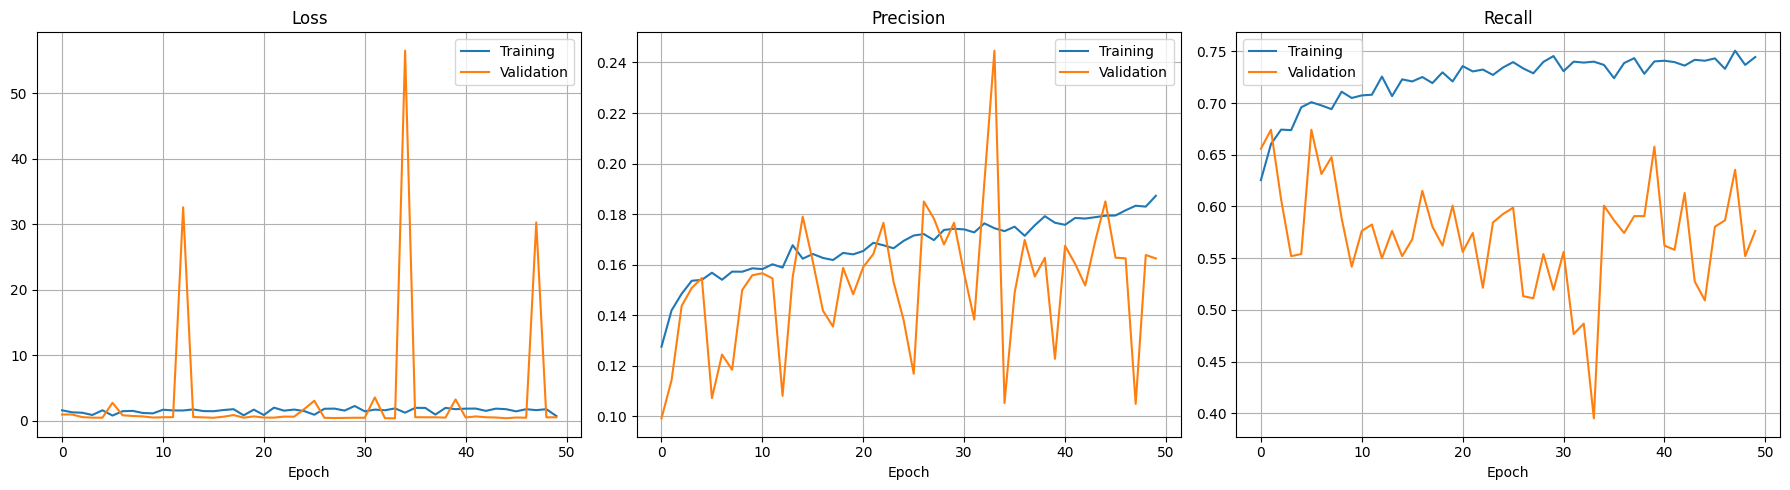

In [51]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history_baseline.history["loss"],label="Training")
axes[0].plot(history_baseline.history["val_loss"],label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid()


axes[1].plot(history_baseline.history["precision"],label="Training")
axes[1].plot(history_baseline.history["val_precision"],label="Validation")
axes[1].set_title("Precision")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid()


axes[2].plot(history_baseline.history["recall"],label="Training")
axes[2].plot(history_baseline.history["val_recall"],label="Validation")
axes[2].set_title("Recall")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.show()

# model 2

In [27]:
model_baseline = build_baseline_model(
    X_train_processed.shape[1]
,256)

history_baseline = model_baseline.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    verbose=1
)

E0000 00:00:1795327506.863448      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - f1_score: 0.2171 - loss: 1.5823 - precision: 0.1311 - recall: 0.6317 - val_f1_score: 0.2286 - val_loss: 0.5600 - val_precision: 0.1432 - val_recall: 0.5662
Epoch 2/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2391 - loss: 2.2122 - precision: 0.1455 - recall: 0.6697 - val_f1_score: 0.1627 - val_loss: 8.7287 - val_precision: 0.0909 - val_recall: 0.7760
Epoch 3/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2420 - loss: 1.7812 - precision: 0.1476 - recall: 0.6715 - val_f1_score: 0.2226 - val_loss: 0.4680 - val_precision: 0.1406 - val_recall: 0.5336
Epoch 4/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2529 - loss: 1.8494 - precision: 0.1552 - recall: 0.6821 - val_f1_score: 0.1727 - val_loss: 6.1181 - val_precision: 0.0999 - val_recall: 0.6375
Epoch 5/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2525 - loss: 1.7643 - precision: 0.1545 - recall: 0.6909 - val_f1_score: 0.2337 - va

In [28]:
y_val_prob = model_baseline.predict(X_val_processed).ravel()
y_val_pred = (y_val_prob >= 0.5).astype(int)
print(classification_report(y_val,y_val_pred,target_names=["Alive", "Failed"]))
print(confusion_matrix(y_val, y_val_pred))

328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

       Alive       0.98      0.78      0.87      9982
      Failed       0.12      0.65      0.21       491

    accuracy                           0.77     10473
   macro avg       0.55      0.71      0.54     10473
weighted avg       0.94      0.77      0.83     10473

[[7748 2234]
 [ 174  317]]


### model 3

In [29]:
model2 = Sequential()

model2.add(Input(shape=(X_train_processed.shape[1],)))

# Only one hidden layer
model2.add(Dense(128, activation="relu"))
model2.add(Dense(64, activation="relu"))

# Output layer
model2.add(Dense(1, activation="sigmoid"))

model2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold=0.5, name="f1_score")
    ]
)

In [30]:
history_baseline = model2.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - f1_score: 0.2108 - loss: 1.8455 - precision: 0.1273 - recall: 0.6135 - val_f1_score: 0.1897 - val_loss: 0.5930 - val_precision: 0.1143 - val_recall: 0.5580
Epoch 2/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2386 - loss: 1.8674 - precision: 0.1446 - recall: 0.6808 - val_f1_score: 0.1819 - val_loss: 0.6682 - val_precision: 0.1055 - val_recall: 0.6599
Epoch 3/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2487 - loss: 1.3056 - precision: 0.1512 - recall: 0.6997 - val_f1_score: 0.2239 - val_loss: 0.4666 - val_precision: 0.1367 - val_recall: 0.6171
Epoch 4/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2582 - loss: 0.7827 - precision: 0.1574 - recall: 0.7184 - val_f1_score: 0.2197 - val_loss: 0.4964 - val_precision: 0.1325 - val_recall: 0.6415
Epoch 5/50
1748/1748 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - f1_score: 0.2586 - loss: 0.9054 - precision: 0.1570 - recall: 0.7330 - val_f1_score: 0.1929 - va

In [31]:
y_val_prob = model_baseline.predict(X_val_processed).ravel()
y_val_pred = (y_val_prob >= 0.5).astype(int)
print(classification_report(y_val,y_val_pred,target_names=["Alive", "Failed"]))
print(confusion_matrix(y_val, y_val_pred))

328/328 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

       Alive       0.98      0.78      0.87      9982
      Failed       0.12      0.65      0.21       491

    accuracy                           0.77     10473
   macro avg       0.55      0.71      0.54     10473
weighted avg       0.94      0.77      0.83     10473

[[7748 2234]
 [ 174  317]]


# Hyperparameter tunning

In [71]:
def objective(trial):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(21)

    n_layers = trial.suggest_int("n_layers", 1,5)
    learning_rate = trial.suggest_float("learning_rate",0.0001,0.01,log=True)
    batch_size = trial.suggest_int("batch_size",32,256)
    optimizer_name = trial.suggest_categorical("optimizer",["adam", "rmsprop", "sgd"])
    epochs = trial.suggest_int("epochs",30,150)

    model = Sequential()

    model.add(Input(shape=(X_train_processed.shape[1],)))

    for i in range(n_layers):
        units = trial.suggest_int(f"units_layer_{i+1}",8,256)
        dropout_rate = trial.suggest_float(f"dropout_layer_{i+1}",0.0,0.4,step=0.1)
        activation = trial.suggest_categorical(f"activation_layer_{i+1}",["relu"])
        
        model.add(Dense(units=units,activation=activation))

        if dropout_rate > 0:
            model.add(Dropout(rate=dropout_rate))
            
    model.add(Dense(1, activation="sigmoid"))

    if optimizer_name == "adam":
        optimizer = Adam(learning_rate=learning_rate)
    elif optimizer_name == "rmsprop":
        optimizer = RMSprop(learning_rate=learning_rate)
    else:
        optimizer = SGD(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),tf.keras.metrics.F1Score(threshold=0.5, name="f1_score")])

    early_stop = EarlyStopping(monitor="val_f1_score",
                               mode="max",
                               patience=10,
                               restore_best_weights=True,
                               verbose=0)

    history = model.fit(
        X_train_processed,
        y_train,
        validation_data=(
            X_val_processed,
            y_val
        ),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0)
    
    best_f1 = float(max(history.history["val_f1_score"]))

    return best_f1

In [72]:
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed =21))

[I 2026-11-22 15:40:37,845] A new study created in memory with name: no-name-70cc297e-7b65-471f-bd30-0424d273b5a6


In [73]:
study.optimize(objective,n_trials=100)

[I 2026-11-22 15:41:24,372] Trial 0 finished with value: 0.24405282735824585 and parameters: {'n_layers': 1, 'learning_rate': 0.000378633747241908, 'batch_size': 194, 'optimizer': 'rmsprop', 'epochs': 66, 'units_layer_1': 173, 'dropout_layer_1': 0.1, 'activation_layer_1': 'relu'}. Best is trial 0 with value: 0.24405282735824585.
[I 2026-11-22 15:42:03,293] Trial 1 finished with value: 0.12730900943279266 and parameters: {'n_layers': 3, 'learning_rate': 0.00013776595567280885, 'batch_size': 227, 'optimizer': 'sgd', 'epochs': 134, 'units_layer_1': 196, 'dropout_layer_1': 0.4, 'activation_layer_1': 'relu', 'units_layer_2': 197, 'dropout_layer_2': 0.1, 'activation_layer_2': 'relu', 'units_layer_3': 109, 'dropout_layer_3': 0.30000000000000004, 'activation_layer_3': 'relu'}. Best is trial 0 with value: 0.24405282735824585.
[I 2026-11-22 15:42:45,826] Trial 2 finished with value: 0.3106795847415924 and parameters: {'n_layers': 2, 'learning_rate': 0.005107469054556476, 'batch_size': 237, 'opti

In [74]:
print("Best Trial:", study.best_trial.number)
print("Best F1-score:", study.best_value)

print("\nBest Hyperparameters:")
for key, value in study.best_params.items():
    print(f"{key}: {value}")


Best Trial: 83
Best F1-score: 0.3630307614803314

Best Hyperparameters:
n_layers: 2
learning_rate: 0.0011923562515367178
batch_size: 207
optimizer: adam
epochs: 135
units_layer_1: 249
dropout_layer_1: 0.1
activation_layer_1: relu
units_layer_2: 53
dropout_layer_2: 0.4
activation_layer_2: relu


# Model after hyper parameter tunnig

In [79]:

model_tuned = Sequential()

#inout layer
model_tuned.add(Input(shape = (X_train_processed.shape[1],)))

#hidden layers
model_tuned.add(Dense(units = 249,activation='relu'))
model_tuned.add(Dropout (0.1))
model_tuned.add(Dense(units = 53,activation='relu'))
model_tuned.add(Dropout (0.4))

#output layer
model_tuned.add(Dense(units = 1 ,activation = 'sigmoid'))

# Optimizer
optimizer = Adam(learning_rate = 0.0011923562515367178)

# Compile
model_tuned.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(name="pr_auc", curve="PR")
    ]
)

model_tuned.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 249)            │        25,398 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 249)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 53)             │        13,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 53)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            54 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,702 (151.18 KB)

 Trainable params: 38,702 (151.18 KB)

 Non-trainable params: 0 (0.00 B)

In [80]:
early_stop = EarlyStopping(monitor="val_pr_auc",mode="max",patience=10,
    restore_best_weights=True)

history = model_tuned.fit(X_train_processed,y_train,
                    validation_data=(X_val_processed,y_val),
                    epochs=135,
                    batch_size=207,
                    class_weight=class_weights,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/135
271/271 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5429 - loss: 1.3450 - pr_auc: 0.1110 - precision: 0.1052 - recall: 0.6337 - roc_auc: 0.6088 - val_accuracy: 0.6253 - val_loss: 0.5945 - val_pr_auc: 0.1422 - val_precision: 0.0808 - val_recall: 0.6741 - val_roc_auc: 0.7149
Epoch 2/135
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5431 - loss: 0.6565 - pr_auc: 0.1432 - precision: 0.1146 - recall: 0.7069 - roc_auc: 0.6727 - val_accuracy: 0.6592 - val_loss: 0.5109 - val_pr_auc: 0.1609 - val_precision: 0.0867 - val_recall: 0.6578 - val_roc_auc: 0.7437
Epoch 3/135
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5433 - loss: 0.6426 - pr_auc: 0.1672 - precision: 0.1189 - recall: 0.7407 - roc_auc: 0.7006 - val_accuracy: 0.7895 - val_loss: 0.4460 - val_pr_auc: 0.1782 - val_precision: 0.1251 - val_recall: 0.5825 - val_roc_auc: 0.7653
Epoch 4/135
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5461 - loss: 0.6367 - pr_auc: 0.1707 - precision: 0.1219 - recall:

In [82]:
print("Model_tuned")

y_probability = model_tuned.predict(X_test_processed).ravel()
y_pred = (y_probability >= 0.).astype(int)

print(classification_report(y_result, y_pred, target_names=["Alive", "Failed"]))
print("Confusion Matrix:")
print(confusion_matrix(y_result, y_pred))
print("Precision: ", precision_score(y_result, y_pred))
print("Recall: ", recall_score(y_result, y_pred))
print("F1_score: ", f1_score(y_result, y_pred))


Model_tuned
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
              precision    recall  f1-score   support

       Alive       0.00      0.00      0.00     11995
      Failed       0.02      1.00      0.05       287

    accuracy                           0.02     12282
   macro avg       0.01      0.50      0.02     12282
weighted avg       0.00      0.02      0.00     12282

Confusion Matrix:
[[    0 11995]
 [    0   287]]
Precision:  0.023367529718286924
Recall:  1.0
F1_score:  0.04566791311957992


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# optuna 2

In [45]:

def create_objective(metric_name):

    def objective(trial):

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(21)

        n_layers = trial.suggest_int("n_layers", 1, 4)
        learning_rate = trial.suggest_float("learning_rate",0.0001,0.01,log=True)
        batch_size = trial.suggest_categorical("batch_size",[32, 64, 128, 256])
        optimizer_name = trial.suggest_categorical("optimizer",["adam", "rmsprop", "sgd"])
        threshold = trial.suggest_float("threshold",0.05,0.95,step=0.01)
        model = Sequential()
        model.add(Input(shape=(X_train_processed.shape[1],)))

        for i in range(n_layers):
            units = trial.suggest_categorical(f"units_layer_{i+1}",[32, 64, 128, 256])
            dropout_rate = trial.suggest_float(f"dropout_layer_{i+1}",0.0,0.4,step=0.1)
            activation = trial.suggest_categorical(f"activation_layer_{i+1}",["relu", "tanh"])
            model.add(
                Dense(units=units,activation=activation))
            if dropout_rate > 0:
                model.add(Dropout(dropout_rate))
        model.add(Dense(1, activation="sigmoid"))


        if optimizer_name == "adam":
            optimizer = Adam(learning_rate=learning_rate)
        elif optimizer_name == "rmsprop":
            optimizer = RMSprop(learning_rate=learning_rate)
        else:
            optimizer = SGD(learning_rate=learning_rate)


        model.compile(
            optimizer=optimizer,
            loss="binary_crossentropy",
            metrics=[tf.keras.metrics.AUC(curve="PR",name="pr_auc")])


        early_stop = EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=10,
            restore_best_weights=True,
            verbose=0)
        history = model.fit(
            X_train_processed,
            y_train,
            validation_data=(X_val_processed,y_val),
            epochs=150,
            batch_size=batch_size,class_weight=class_weights,callbacks=[early_stop],verbose=0)


        val_probabilities = model.predict(X_val_processed,verbose=0).ravel()
        val_predictions = (val_probabilities >= threshold).astype(int)
        precision = precision_score(y_val,val_predictions,zero_division=0)
        recall = recall_score(y_val,val_predictions,zero_division=0)
        f1 = f1_score(y_val,val_predictions,zero_division=0)

        trial.set_user_attr("precision", float(precision))
        trial.set_user_attr("recall", float(recall))
        trial.set_user_attr("f1_score", float(f1))
        trial.set_user_attr("threshold", float(threshold))
        trial.set_user_attr("best_pr_auc",float(max(history.history["val_pr_auc"])))
        if metric_name == "precision":
            if recall < 0.30:
                return 0.0
            return float(precision)
        elif metric_name == "recall":

            if precision < 0.10:
                return 0.0
            return float(recall)
        elif metric_name == "f1":
            return float(f1)
    return objective


In [46]:
study_precision = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=21)
)

study_precision.optimize(
    create_objective("precision"),
    n_trials=50,
    n_jobs=1,
    show_progress_bar=True
)

[I 2026-11-23 06:49:26,934] A new study created in memory with name: no-name-c8a97ca0-3914-4b21-a1c7-db608daf649f


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-11-23 06:50:41,272] Trial 0 finished with value: 0.1997907949790795 and parameters: {'n_layers': 1, 'learning_rate': 0.000378633747241908, 'batch_size': 32, 'optimizer': 'rmsprop', 'threshold': 0.5800000000000001, 'units_layer_1': 64, 'dropout_layer_1': 0.2, 'activation_layer_1': 'relu'}. Best is trial 0 with value: 0.1997907949790795.
[I 2026-11-23 06:52:08,549] Trial 1 finished with value: 0.2008 and parameters: {'n_layers': 4, 'learning_rate': 0.00330069279804087, 'batch_size': 128, 'optimizer': 'rmsprop', 'threshold': 0.52, 'units_layer_1': 256, 'dropout_layer_1': 0.2, 'activation_layer_1': 'relu', 'units_layer_2': 128, 'dropout_layer_2': 0.30000000000000004, 'activation_layer_2': 'relu', 'units_layer_3': 256, 'dropout_layer_3': 0.2, 'activation_layer_3': 'tanh', 'units_layer_4': 64, 'dropout_layer_4': 0.1, 'activation_layer_4': 'relu'}. Best is trial 1 with value: 0.2008.
[I 2026-11-23 06:57:20,214] Trial 2 finished with value: 0.0 and parameters: {'n_layers': 2, 'learning

In [51]:
print("Best Precision:", study_precision.best_value)

print("\nBest Parameters:")

for key, value in study_precision.best_trial.params.items():
    print(f"{key}: {value}")

print("\nValidation Recall:",
      study_precision.best_trial.user_attrs["recall"])

print("Validation F1:",
      study_precision.best_trial.user_attrs["f1_score"])

Best Precision: 0.36363636363636365

Best Parameters:
n_layers: 3
learning_rate: 0.0006622442381609686
batch_size: 128
optimizer: rmsprop
threshold: 0.7000000000000001
units_layer_1: 64
dropout_layer_1: 0.2
activation_layer_1: relu
units_layer_2: 256
dropout_layer_2: 0.30000000000000004
activation_layer_2: tanh
units_layer_3: 128
dropout_layer_3: 0.1
activation_layer_3: relu

Validation Recall: 0.31771894093686354
Validation F1: 0.3391304347826087


In [21]:

def objective_refined(trial):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(21)

    n_layers = trial.suggest_categorical("n_layers", [3, 4])
    learning_rate = trial.suggest_categorical("learning_rate",[0.0002518618998031955,0.0006622442381609686,0.0022833657973117443])
    batch_size = trial.suggest_categorical("batch_size", [128])
    optimizer_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop"])
    threshold = trial.suggest_categorical("threshold", [0.06, 0.18, 0.70])


    model = Sequential()
    model.add(
        Input(shape=(X_train_processed.shape[1],)))
    for i in range(n_layers):
        layer_number = i + 1
        if layer_number == 1:
            units_choices = [64, 128]
            dropout_choices = [0.2, 0.3, 0.4]
            activation_choices = ["relu"]
        elif layer_number == 2:
            units_choices = [32, 256]
            dropout_choices = [0.2, 0.3]
            activation_choices = ["relu", "tanh"]
        elif layer_number == 3:
            units_choices = [128]
            dropout_choices = [0.1, 0.3, 0.4]
            activation_choices = ["relu", "tanh"]
        else:
            units_choices = [64]
            dropout_choices = [0.2]
            activation_choices = ["relu"]
        units = trial.suggest_categorical(f"units_layer_{layer_number}",units_choices)
        dropout_rate = trial.suggest_categorical(f"dropout_layer_{layer_number}",dropout_choices)
        activation = trial.suggest_categorical(f"activation_layer_{layer_number}",activation_choices)
        model.add(Dense(units=units,activation=activation))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation="sigmoid"))


    if optimizer_name == "adam":
        optimizer = Adam(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(
            curve="PR",
                name="pr_auc")])


    early_stop = EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=0)

    history = model.fit(X_train_processed,y_train,
        validation_data=(X_val_processed,y_val),
        epochs=150,
        batch_size=batch_size,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0)


    val_probabilities = model.predict(X_val_processed,verbose=0).ravel()
    val_predictions = (val_probabilities >= threshold).astype(int)
    precision = precision_score(y_val,val_predictions,zero_division=0)
    recall = recall_score(y_val,val_predictions,zero_division=0)
    f1 = f1_score(y_val,val_predictions,zero_division=0)
    pr_auc = max(history.history["val_pr_auc"])


    trial.set_user_attr("precision", float(precision))
    trial.set_user_attr("recall", float(recall))
    trial.set_user_attr("f1_score", float(f1))
    trial.set_user_attr("pr_auc", float(pr_auc))

    return float(f1)
              

In [22]:
study_refined = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)

study_refined.optimize(
    objective_refined,
    n_trials=100,
    n_jobs=1,
    show_progress_bar=True
)

[I 2026-11-23 15:09:48,745] A new study created in memory with name: no-name-6b6839e6-dbee-4a0c-8d98-72511bc9deff


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-11-23 15:11:54,182] Trial 0 finished with value: 0.1326530612244898 and parameters: {'n_layers': 4, 'learning_rate': 0.0002518618998031955, 'batch_size': 128, 'optimizer': 'adam', 'threshold': 0.06, 'units_layer_1': 128, 'dropout_layer_1': 0.2, 'activation_layer_1': 'relu', 'units_layer_2': 256, 'dropout_layer_2': 0.2, 'activation_layer_2': 'tanh', 'units_layer_3': 128, 'dropout_layer_3': 0.4, 'activation_layer_3': 'tanh', 'units_layer_4': 64, 'dropout_layer_4': 0.2, 'activation_layer_4': 'relu'}. Best is trial 0 with value: 0.1326530612244898.
[I 2026-11-23 15:13:01,709] Trial 1 finished with value: 0.14086687306501547 and parameters: {'n_layers': 4, 'learning_rate': 0.0022833657973117443, 'batch_size': 128, 'optimizer': 'adam', 'threshold': 0.18, 'units_layer_1': 64, 'dropout_layer_1': 0.2, 'activation_layer_1': 'relu', 'units_layer_2': 32, 'dropout_layer_2': 0.2, 'activation_layer_2': 'relu', 'units_layer_3': 128, 'dropout_layer_3': 0.3, 'activation_layer_3': 'relu', 'units_

In [23]:
best_trial = study_refined.best_trial

print("Best Trial:", best_trial.number)

print("Best Validation F1:", best_trial.value)

print("\nBest Hyperparameters:")

for key, value in best_trial.params.items():
    print(f"{key}: {value}")

print("\nValidation Precision:",
      best_trial.user_attrs["precision"])

print("Validation Recall:",
      best_trial.user_attrs["recall"])

print("Validation PR-AUC:",
      best_trial.user_attrs["pr_auc"])

Best Trial: 95
Best Validation F1: 0.3941908713692946

Best Hyperparameters:
n_layers: 4
learning_rate: 0.0006622442381609686
batch_size: 128
optimizer: adam
threshold: 0.7
units_layer_1: 128
dropout_layer_1: 0.3
activation_layer_1: relu
units_layer_2: 32
dropout_layer_2: 0.2
activation_layer_2: tanh
units_layer_3: 128
dropout_layer_3: 0.1
activation_layer_3: tanh
units_layer_4: 64
dropout_layer_4: 0.2
activation_layer_4: relu

Validation Precision: 0.40169133192389006
Validation Recall: 0.3869653767820774
Validation PR-AUC: 0.31841346621513367


In [32]:
model_final = Sequential()

#inout layer
model_final.add(Input(shape = (X_train_processed.shape[1],)))

#hidden layers
model_final.add(Dense(units = 128,activation='relu'))
model_final.add(Dropout (0.3))

model_final.add(Dense(units = 32,activation='tanh'))
model_final.add(Dropout (0.2))

model_final.add(Dense(units = 128,activation='tanh'))
model_final.add(Dropout (0.1))

model_final.add(Dense(units = 64,activation='relu'))
model_final.add(Dropout (0.2))


#output layer
model_final.add(Dense(units = 1 ,activation = 'sigmoid'))

# Optimizer
optimizer = Adam(learning_rate = 0.0006622442381609686)

# Compile
model_final.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold = 0.7,name="f1_score")])

In [33]:
early_stop = EarlyStopping(monitor="val_f1_score",mode="max",patience=10,
    restore_best_weights=True)

history = model_final.fit(X_train_processed,y_train,
                    validation_data=(X_val_processed,y_val),
                    epochs=100,
                    batch_size=128,
                    class_weight=class_weights,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6010 - f1_score: 0.0982 - loss: 0.6716 - precision: 0.1120 - recall: 0.5808 - val_accuracy: 0.7389 - val_f1_score: 0.1884 - val_loss: 0.5580 - val_precision: 0.1099 - val_recall: 0.6436
Epoch 2/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6058 - f1_score: 0.1653 - loss: 0.6466 - precision: 0.1245 - recall: 0.6571 - val_accuracy: 0.7491 - val_f1_score: 0.2368 - val_loss: 0.5402 - val_precision: 0.1141 - val_recall: 0.6436
Epoch 3/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6116 - f1_score: 0.1829 - loss: 0.6320 - precision: 0.1305 - recall: 0.6869 - val_accuracy: 0.7179 - val_f1_score: 0.2172 - val_loss: 0.5628 - val_precision: 0.1087 - val_recall: 0.6965
Epoch 4/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6257 - f1_score: 0.2088 - loss: 0.6232 - precision: 0.1354 - recall: 0.6893 - val_accuracy: 0.7439 - val_f1_score: 0.2483 - val_loss: 0.5481 - val_precision: 0.1130 - val_rec

In [34]:
print("final_model")

y_probability = model_final.predict(X_test_processed).ravel()
y_pred = (y_probability >= 0.7).astype(int)

print(classification_report(y_result, y_pred, target_names=["Alive", "Failed"]))
print("Confusion Matrix:")
print(confusion_matrix(y_result, y_pred))
print("Precision: ", precision_score(y_result, y_pred))
print("Recall: ", recall_score(y_result, y_pred))
print("F1_score: ", f1_score(y_result, y_pred))


final_model
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
              precision    recall  f1-score   support

       Alive       0.98      0.96      0.97     11995
      Failed       0.17      0.33      0.23       287

    accuracy                           0.95     12282
   macro avg       0.58      0.64      0.60     12282
weighted avg       0.96      0.95      0.96     12282

Confusion Matrix:
[[11541   454]
 [  193    94]]
Precision:  0.17153284671532848
Recall:  0.32752613240418116
F1_score:  0.2251497005988024


## Adding the batch normalization so the we can decrease the overfitting issue

In [39]:
model_final_batch = Sequential()

#inout layer
model_final_batch.add(Input(shape = (X_train_processed.shape[1],)))

#hidden layers
model_final_batch.add(Dense(units = 128,activation='relu'))
model_final_batch.add(BatchNormalization())
model_final_batch.add(Dropout (0.3))

model_final_batch.add(Dense(units = 32,activation='tanh'))
model_final_batch.add(BatchNormalization())
model_final_batch.add(Dropout (0.2))

model_final_batch.add(Dense(units = 128,activation='tanh'))
model_final_batch.add(BatchNormalization())
model_final_batch.add(Dropout (0.1))

model_final_batch.add(Dense(units = 64,activation='relu'))
model_final_batch.add(BatchNormalization())
model_final_batch.add(Dropout (0.2))


#output layer
model_final_batch.add(Dense(units = 1 ,activation = 'sigmoid'))

# Optimizer
optimizer = Adam(learning_rate = 0.0006622442381609686)

# Compile
model_final_batch.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold = 0.7,name="f1_score")])

In [40]:
early_stop = EarlyStopping(monitor="val_f1_score",mode="max",patience=10,
    restore_best_weights=True)

history = model_final_batch.fit(X_train_processed,y_train,
                    validation_data=(X_val_processed,y_val),
                    epochs=100,
                    batch_size=128,
                    class_weight=class_weights,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5247 - f1_score: 0.1327 - loss: 0.7600 - precision: 0.0897 - recall: 0.5448 - val_accuracy: 0.2704 - val_f1_score: 0.1607 - val_loss: 0.8085 - val_precision: 0.0548 - val_recall: 0.8961
Epoch 2/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5574 - f1_score: 0.1366 - loss: 0.6992 - precision: 0.1014 - recall: 0.5819 - val_accuracy: 0.3884 - val_f1_score: 0.2140 - val_loss: 0.7751 - val_precision: 0.0642 - val_recall: 0.8880
Epoch 3/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5816 - f1_score: 0.1611 - loss: 0.6704 - precision: 0.1131 - recall: 0.6240 - val_accuracy: 0.4887 - val_f1_score: 0.1388 - val_loss: 0.6925 - val_precision: 0.0717 - val_recall: 0.8289
Epoch 4/100
437/437 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5918 - f1_score: 0.1631 - loss: 0.6560 - precision: 0.1196 - recall: 0.6508 - val_accuracy: 0.5818 - val_f1_score: 0.2255 - val_loss: 0.6512 - val_precision: 0.0819 - val_rec

In [41]:
print("final_model_batch")

y_probability = model_final_batch.predict(X_test_processed).ravel()
y_pred = (y_probability >= 0.7).astype(int)

print(classification_report(y_result, y_pred, target_names=["Alive", "Failed"]))
print("Confusion Matrix:")
print(confusion_matrix(y_result, y_pred))
print("Precision: ", precision_score(y_result, y_pred))
print("Recall: ", recall_score(y_result, y_pred))
print("F1_score: ", f1_score(y_result, y_pred))


final_model_batch
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

       Alive       0.98      0.95      0.97     11995
      Failed       0.15      0.36      0.21       287

    accuracy                           0.94     12282
   macro avg       0.57      0.66      0.59     12282
weighted avg       0.96      0.94      0.95     12282

Confusion Matrix:
[[11412   583]
 [  184   103]]
Precision:  0.15014577259475217
Recall:  0.3588850174216028
F1_score:  0.2117163412127441
